# Lesson 4. The Bloch sphere

**Goal:** see that the state of one qubit is a point on a sphere, and learn to read from that sphere both the amplitudes and the results of measurements in different bases.

## 1. How many numbers really describe a state?

$(\alpha, \beta) \in \mathbb{C}^2 \cong \mathbb{R}^4$, i.e. 4 real numbers. Two of them drop out:

- **normalisation** $|\alpha|^2 + |\beta|^2 = 1$ cuts out the sphere $S^3 \subset \mathbb{R}^4$;
- the **global phase** identifies points that differ by a factor $e^{i\gamma}$, i.e. the quotient $S^3 / U(1)$.

Two numbers remain, and $S^3/U(1) \cong S^2 = \mathbb{CP}^1$ (the Hopf fibration). This is exactly the Bloch sphere.

## 2. Parametrisation

Since $|\alpha|^2 + |\beta|^2 = 1$, we write $|\alpha| = \cos(\theta/2)$, $|\beta| = \sin(\theta/2)$ for $\theta \in [0, \pi]$, and choose the global phase so that $\alpha$ is real:

$$\boxed{\;\alpha = \cos\tfrac{\theta}{2}, \qquad \beta = e^{i\varphi}\sin\tfrac{\theta}{2}\;}$$

- $\theta$ (distance from the north pole) fixes the **moduli**: how much of the state is along $e_0$ and how much along $e_1$. For example $P(0) = \cos^2(\theta/2)$.
- $\varphi$ (longitude, around the $z$ axis) is the **relative phase**: how far $\beta$ is rotated relative to $\alpha$ in the complex plane.

> **This was tricky:** it feels unintuitive that the relative phase is the "longitude". A walk around the equator helps: everywhere on the equator it is 50/50 zero and one ($\theta = \pi/2$ stays fixed), and only the phase shift between them changes. That is why the motion goes around the $z$ axis.

## 3. Map of the sphere and axes as bases

| Point | $\theta$ | $\varphi$ | Label | Vector |
|---|---|---|---|---|
| north pole | 0 | – | $\lvert 0\rangle$ | $(1, 0)$ |
| south pole | $\pi$ | – | $\lvert 1\rangle$ | $(0, 1)$ |
| equator, $+x$ axis | $\pi/2$ | 0 | $\lvert +\rangle$ | $(1, 1)/\sqrt2$ |
| equator, $-x$ axis | $\pi/2$ | $\pi$ | $\lvert -\rangle$ | $(1, -1)/\sqrt2$ |
| equator, $+y$ axis | $\pi/2$ | $\pi/2$ | $\lvert {+i}\rangle$ | $(1, i)/\sqrt2$ |
| equator, $-y$ axis | $\pi/2$ | $-\pi/2$ | $\lvert {-i}\rangle$ | $(1, -i)/\sqrt2$ |

**Why $\theta/2$?** Orthogonal vectors in $\mathbb{C}^2$ (angle 90°) must lie opposite each other on the sphere (angle 180°). Each pair of antipodal points is **one measurement basis**: $z$ axis $\to \{e_0, e_1\}$, $x$ axis $\to \{u_+, u_-\}$, $y$ axis $\to \{|{+i}\rangle, |{-i}\rangle\}$.

## 4. Coordinates of the point and measurement as projection

The point on the sphere in Cartesian coordinates:

$$(x, y, z) = (\sin\theta\cos\varphi,\; \sin\theta\sin\varphi,\; \cos\theta).$$

The same coordinates in terms of amplitudes:

$$z = |\alpha|^2 - |\beta|^2, \qquad x + iy = 2\,\bar\alpha\beta.$$

The projection of the point onto the equatorial plane is exactly the complex number $2\bar\alpha\beta = \sin\theta\, e^{i\varphi}$. The sphere does not show $\alpha$ or $\beta$ separately (they carry the irrelevant global phase), only their relation $\bar\alpha\beta$. This is exactly the quantity that produced the interference term in lesson 3.

**A measurement in a given basis is a projection onto the corresponding axis:**

$$P(0) = \frac{1 + z}{2}, \qquad P(+) = \frac{1 + x}{2}, \qquad P(+i) = \frac{1 + y}{2}.$$

The formula $P(+) = \tfrac12(1 + 2|\alpha||\beta|\cos\varphi)$ from lesson 3 is the same, since $2|\alpha||\beta| = 2\cos\tfrac\theta2\sin\tfrac\theta2 = \sin\theta$.

**The puzzle from lesson 3:** the states $|{+i}\rangle$ and $|{-i}\rangle$ lie on the $y$ axis, so both have $x = 0$ and $z = 0$. In the $z$ and $x$ bases both give 50/50; only a measurement along the $y$ axis tells them apart. That is why reconstructing an unknown state requires measurements in **three** bases (state tomography).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # label |0⟩
e1 = np.array([0, 1], dtype=complex)   # label |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Print a state vector with bit labels (label = position written in binary)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  position {k} ({format(k, f'0{n}b')}): amplitude {np.round(a, 3)}, P = {abs(a)**2:.3f}")

def amplitudes(theta, phi):
    return np.array([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)])

def bloch(v):
    """Coordinates (x, y, z) of the state v on the Bloch sphere."""
    a, b = v
    c = 2 * np.conj(a) * b
    return np.array([c.real, c.imag, abs(a) ** 2 - abs(b) ** 2])

up, um = (e0 + e1) / np.sqrt(2), (e0 - e1) / np.sqrt(2)
theta, phi = np.pi / 3, np.pi / 4
v = amplitudes(theta, phi)
x, y, z = bloch(v)
print("amplitudes:", np.round(v, 3))
print("(x, y, z) =", np.round([x, y, z], 3))
print(f"P(0) from the Born rule: {abs(v[0])**2:.3f}   from the projection (1+z)/2: {(1+z)/2:.3f}")
print(f"P(+) from the Born rule: {abs(np.vdot(up, v))**2:.3f}   from the projection (1+x)/2: {(1+x)/2:.3f}")

amplitudes: [0.866+0.j    0.354+0.354j]
(x, y, z) = [0.612 0.612 0.5  ]
P(0) from the Born rule: 0.750   from the projection (1+z)/2: 0.750
P(+) from the Born rule: 0.806   from the projection (1+x)/2: 0.806

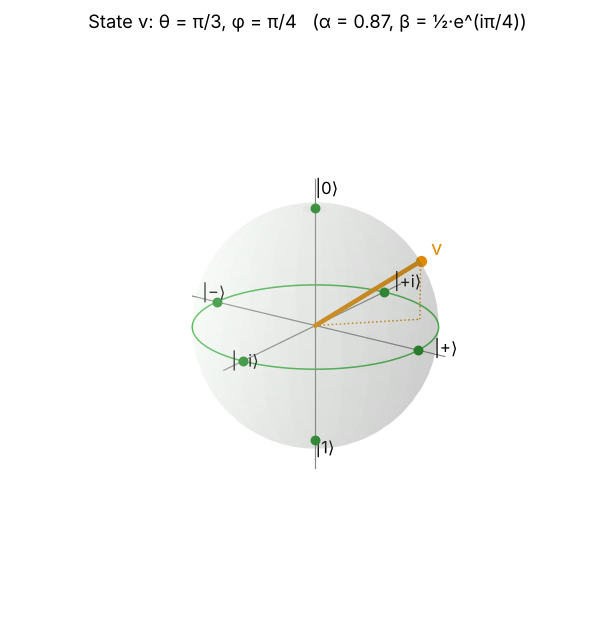

In [2]:
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(111, projection="3d")
ax.view_init(elev=20, azim=-55); ax.set_box_aspect((1, 1, 1))
u_, w_ = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
ax.plot_surface(np.cos(u_)*np.sin(w_), np.sin(u_)*np.sin(w_), np.cos(w_), color="#EAF7EA", alpha=0.15, lw=0)
t = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(t), np.sin(t), 0, color=GREEN, lw=1)
for d in np.eye(3):
    ax.plot(*np.c_[-1.25*d, 1.25*d], color=GREY, lw=0.8)
for p, l in [((0,0,1),"|0⟩"), ((0,0,-1),"|1⟩"), ((1,0,0),"|+⟩"), ((-1,0,0),"|−⟩"), ((0,1,0),"|+i⟩"), ((0,-1,0),"|−i⟩")]:
    ax.scatter(*p, color=DARK, s=30); ax.text(p[0]*1.15, p[1]*1.15, p[2]*1.12, l, fontsize=11)
ax.plot([0, x], [0, y], [0, z], color=ORANGE, lw=3); ax.scatter(x, y, z, color=ORANGE, s=40)
ax.text(x*1.1, y*1.1, z*1.1, "v", color=ORANGE, fontsize=13)
ax.plot([x, x], [y, y], [z, 0], color=ORANGE, ls=":", lw=1); ax.plot([0, x], [0, y], [0, 0], color=ORANGE, ls=":", lw=1)
ax.set_axis_off(); ax.set_title(f"State v: θ = π/3, φ = π/4   (α = {v[0].real:.2f}, β = ½·e^(iπ/4))")

## 5. A limitation

The Bloch sphere works only for **one** qubit. The state of two qubits lives in $\mathbb{C}^4$, and an entangled state cannot be drawn as two points on two spheres (lesson 7). A single qubit taken out of a Bell state corresponds to the centre of the ball, not to a point on the sphere. Interior points are mixed states (density matrices), which are beyond this course.

## Summary

> The state of a qubit is a point on the sphere $S^2$: $\alpha = \cos\frac\theta2$, $\beta = e^{i\varphi}\sin\frac\theta2$. The height ($\theta$) says how much zero and how much one; the longitude ($\varphi$) is the relative phase. Antipodal points are orthogonal states, and each axis is one measurement basis. A measurement in a given basis is the projection of the point onto that axis: $P = (1 + \text{coordinate})/2$.

## Exercises

1. Where on the sphere is the state $(\sqrt3/2, 1/2)$? Give $\theta$ and $\varphi$.
2. A state has $\theta = \pi/3$, $\varphi = \pi$. Write it as $(\alpha, \beta)$ and compute $P(0)$ and $P(+)$.
3. Why can no point of the sphere give both $P(0) = 1$ and $P(+) = 1$?